# RetroPath 2.0: workflow e utilizzo

## Introduzione
Per riuscire a sviluppare un tool che possa predire pathway metabolici non annotati e/o sufficientemente curati sui database pubblici (KEGG, MetaCyc, MetaNetX...), ci serviamo di RetroPath 2.0, un algoritmo di retrosintesi atto a trovare possibili _reazioni_ (e relativi enzimi) che colleghino i _composti target_ (source compounds) ai _metaboliti principali_ (sink compounds) presenti nel metabolismo del batterio che va ingegnerizzato.

Per fare ciò, una serie di reaction rules sono applicate iterativamente sui composti fino a raggiungere una condizione di stop (tipicamente il raggiungimento dei sink o il numero di iterazioni). Le reaction rules in generale non sono altro che una descrizione delle modifiche strutturali che avvengono in una molecola quando si passa da reagenti a prodotti. Nel caso della retrosintesi le regole sono invertite, così da calcolare i reagenti a partire dai prodotti.

Integrando questo workflow con i nostri scopi di biorisanamento, confidiamo di essere in grado di sviluppare un tool che possa predire i pathway di degradazione degli inquinanti meno conosciuti/annotati, considerando proprio questi ultimi come i source compounds e i composti del metabolismo centrale come i sink compounds.

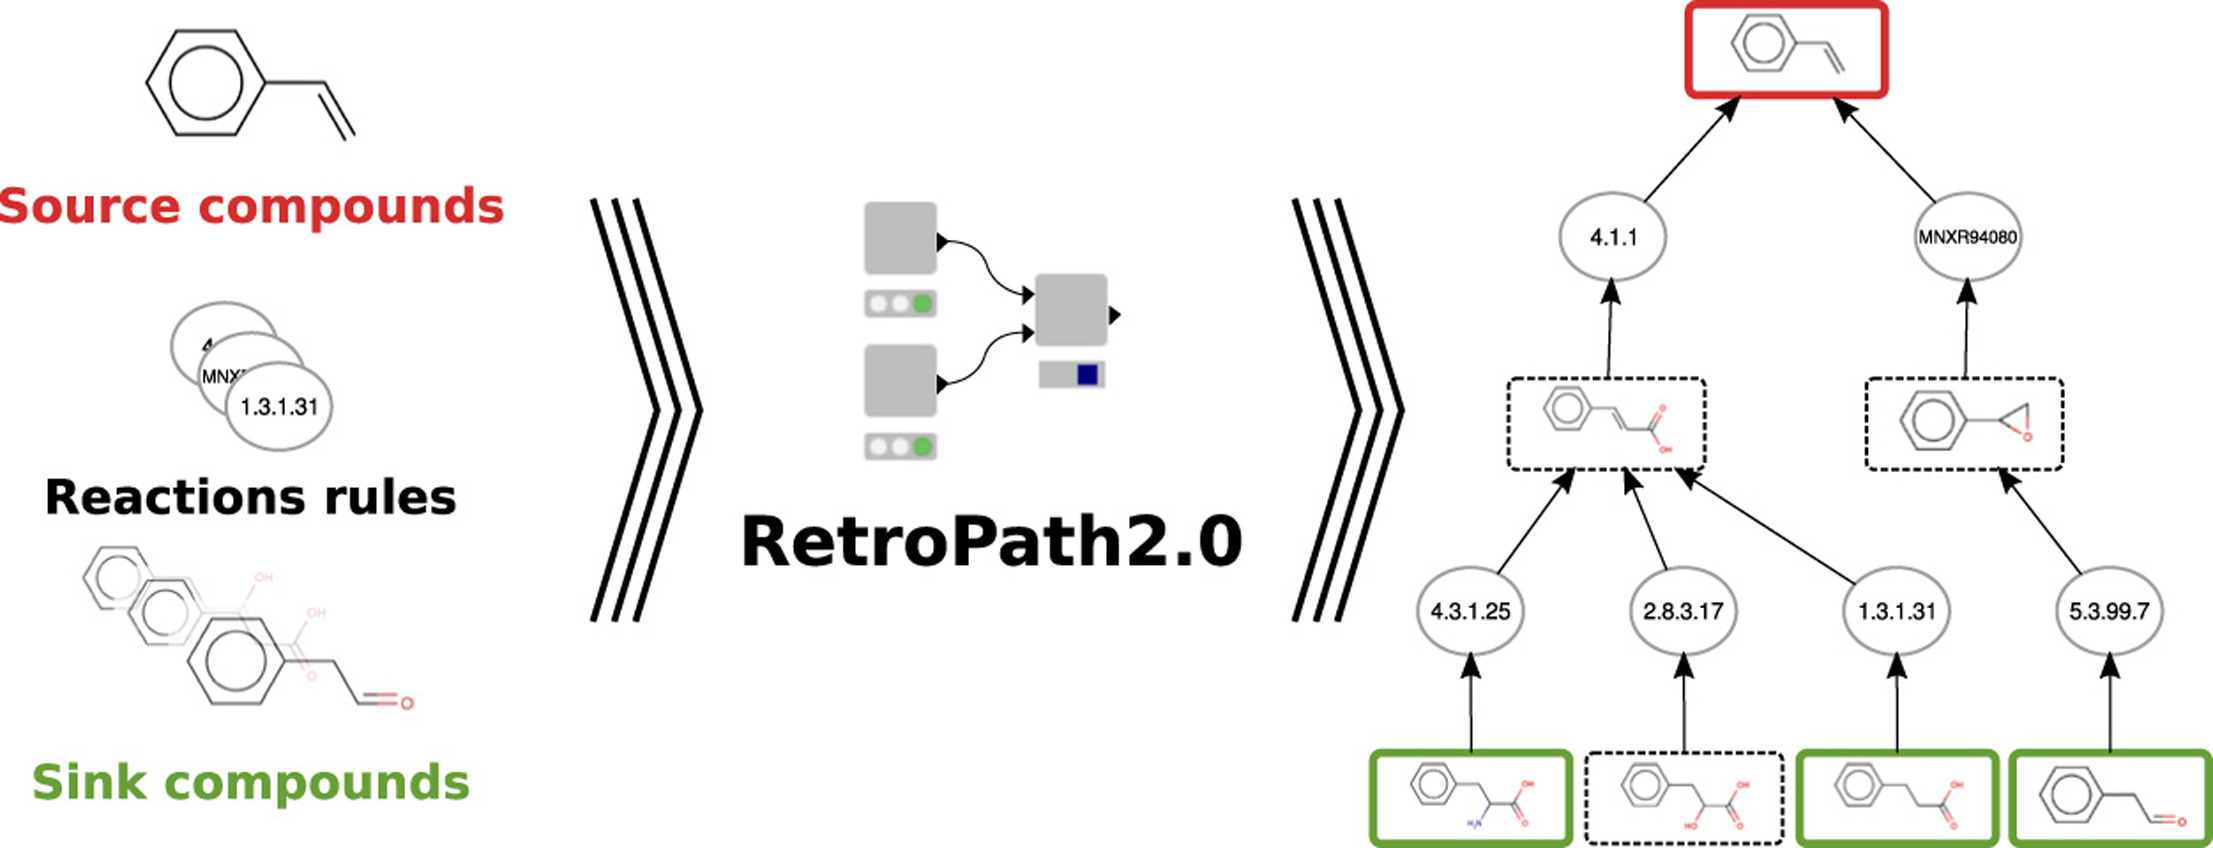

## Input e output
Come anticipato, il tool richiede in input tre elementi: il composto target (ciò che si vuole degradare, *source compound*), i metaboliti centrali (ciò a cui si vuole arrivare, *sink compounds*) e le *reactions rules*. Queste ultime possono essere ottenute con una query al database di **RetroRules**, filtrando per il nome del substrato o la sua struttura molecolare (rappresentata dall'*International Chemical Identifier* - InChI). 

Il formato di tutti e tre è .csv: sia *source* che *sink* seguono la struttura 'Name', 'InChI'; le *rules* hanno invece un numero maggiore di colonne, ma quelle più informative sono quelle dell'**EC number**, del **diameter**, e dello **score**. Il primo parametro riguarda la categoria a cui appartiene l'enzima in grando di compiere quella determinata trasformazione chimica; il secondo misura la specificità della reazione (maggiore diametro = reazione più specifica); il terzo è invece un valore associato alla disponibilità della sequenza enzimatica.

Per quanto concerne l'output, si tratta sempre di un file .csv, contenente tutti gli step di reazione predetti per ogni composto intermedio. È facilmente visualizzabile aprendolo ad esempio con Excel, ed è composto da 14 colonne:
- **Initial source**: composto di partenza che si intende degradare
- **Transformation ID**: specifico per ogni riga, è una numerazione ordinata degli step
- **Reaction SMILES**: rappresentazione della reazione secondo il metodo *Simplified Molecular Input Line Entry System*
- **Substrate SMILES**: rappresentazione del reagente secondo il metodo *Simplified Molecular Input Line Entry System*
- **Substrate InChI**: rappresentazione del reagente secondo l'identificatore InChI
- **Product SMILES**: rappresentazione del prodotto secondo il metodo *Simplified Molecular Input Line Entry System*
- **Product InChI**: rappresentazione del prodotto secondo l'identificatore InChI
- **In Sink**: 1 se il prodotto ottenuto da questa trasformazione fa parte dei *sink compounds*, altrimenti 0
- **Sink name**: se la colonna precedente ha valore 1, contiene il nome del *sink compound*, altrimenti None 
- **Diameter**: diametro, e quindi specificità, della *reaction rule* applicata
- **Rule ID**: ID della *reaction rule* applicata
- **EC number**: Enzyme Code(s) associato/i alla *reaction rule* applicata 
- **Score**: *score* della *reaction rule* applicata, basato sulla disponibilità della sequenza enzimatica
- **Iteration**: numero di trasformazioni applicate fino a quel punto a partire dall'*Initial source*, l'indicizzazione parte da 0

Inoltre, vengono prodotti un .json e un altro .csv, chiamati come il *source compound*, che rappresentano lo **scope**, ovvero il percorso "pulito" che effettivamente parte dal *source* e arriva a dei *sink*. Questo scope sarà poi utile quando usato con **rp2paths**, tool accessorio che stiamo incominciando ad implementare e che permette di estrarre i percorsi singoli fornendo anche una loro visualizzazione grafica.

# Esempio

L'esempio che vogliamo portare mette alla prova il tool lasciandolo spaziare tra le possibili reazioni a partire dal MET, la parte monomerica del PET.
Riteniamo poco informativo riguardo le potenzialità del tool un esempio "guidato", quindi dove i *sink compound* sono un singolo composto che sappiamo a priori essere distante poche reazioni dal composto di partenza. Vogliamo invece testare cosa succede, anche a livello di complessità computazionale, quando i composti di arrivo sono **numerosi** e **generali**, simulando quindi una query plausibile che un utente potrebbe voler fare conoscendo solo il composto che desidera degradare.

Per fare ciò, abbiamo creato un .csv che contiene nome e InChI dei metaboliti centrali di Rhodococcus Opacus. È ad alcuni di questi composti che prevediamo di arrivare applicando *reaction rules* generiche partendo dal *source compound*, ma a differenza di un percorso noto e conosciuto a priori, non sappiamo a priori **quali** possano essere questi composti di arrivo e soprattutto **come** ci si possa arrivare.

Ecco il results.csv che si ottiene eseguendo la query esempio (lunghezza del percorso impostata a 3):

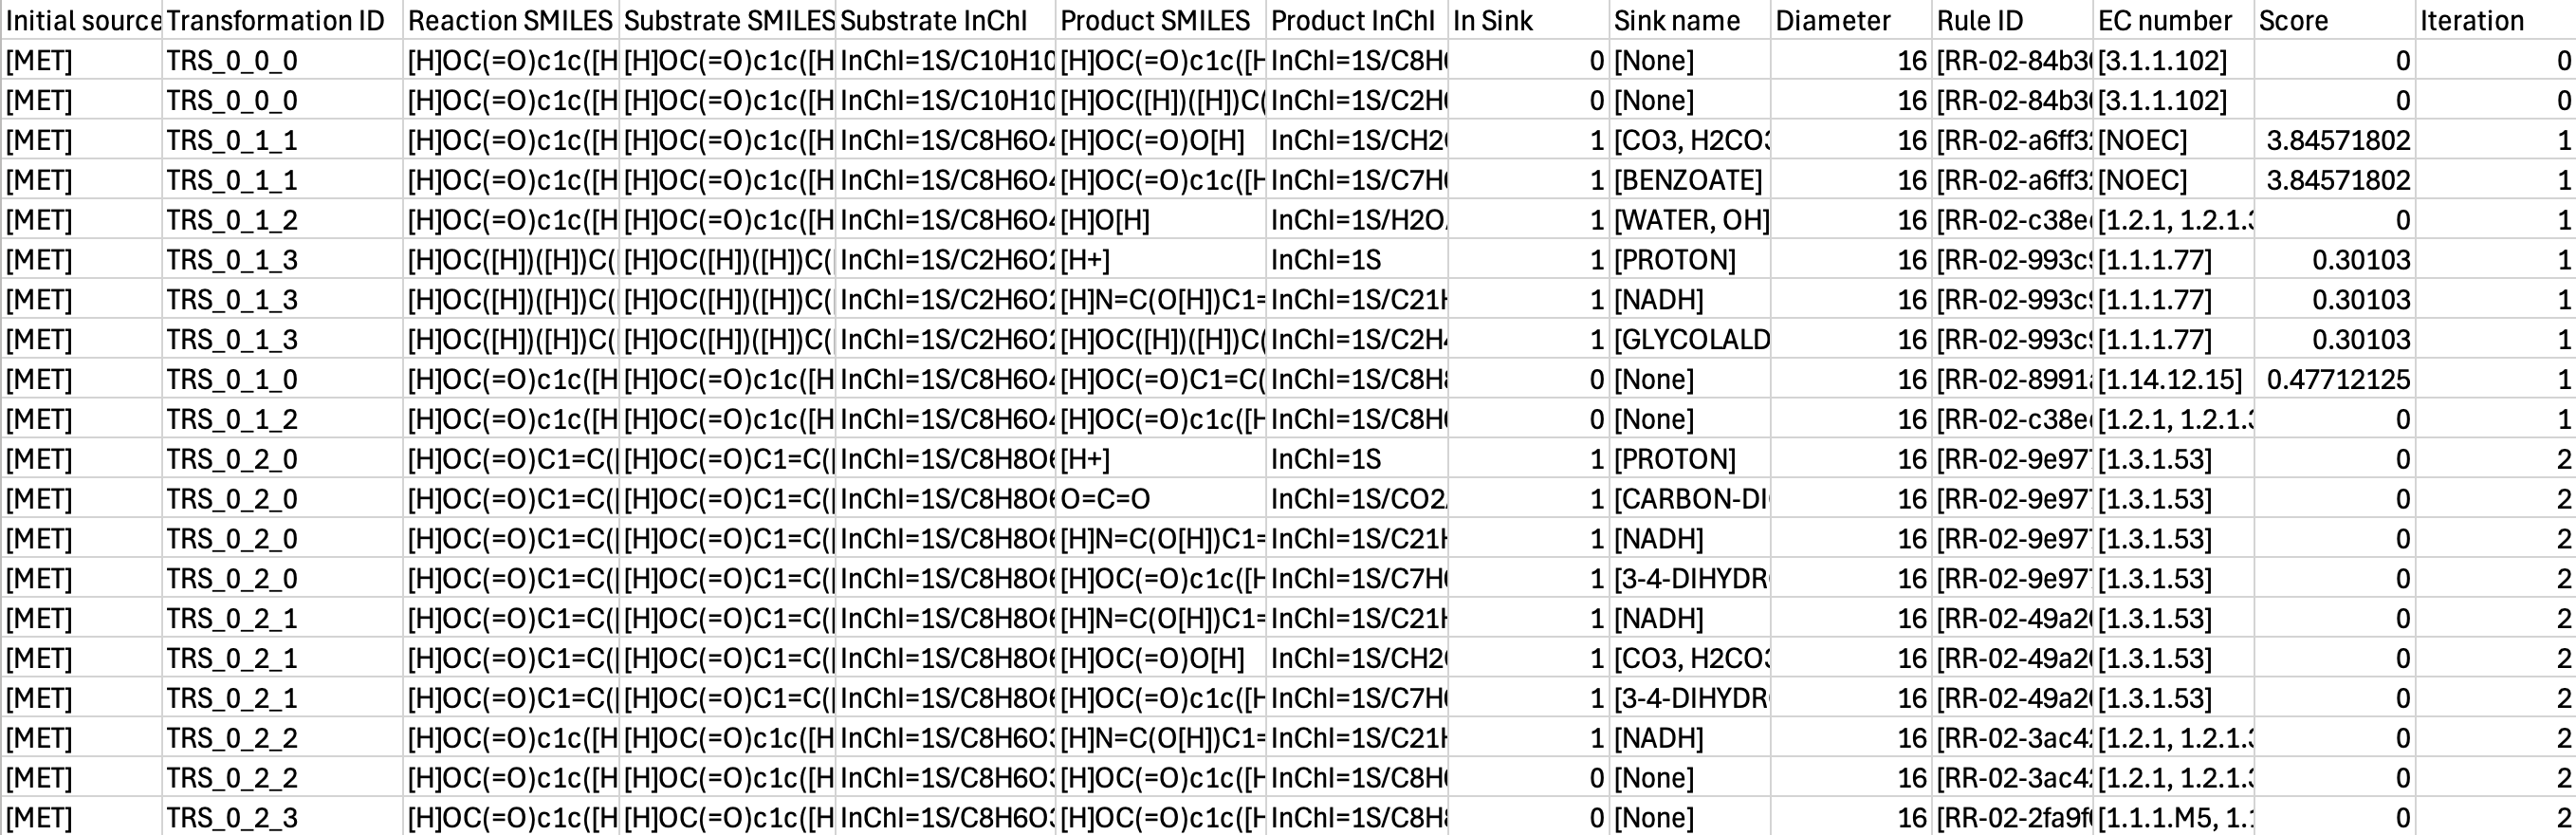

E qui invece MET_scope.csv:

![Screenshot 2025-05-21 alle 22.43.26.png](<attachment:Screenshot 2025-05-21 alle 22.43.26.png>)

Integrando nella pipeline anche rp2paths, dallo scope si generano i vari percorsi, separati e rappresentati graficamente da file in formato .svg e .dot:

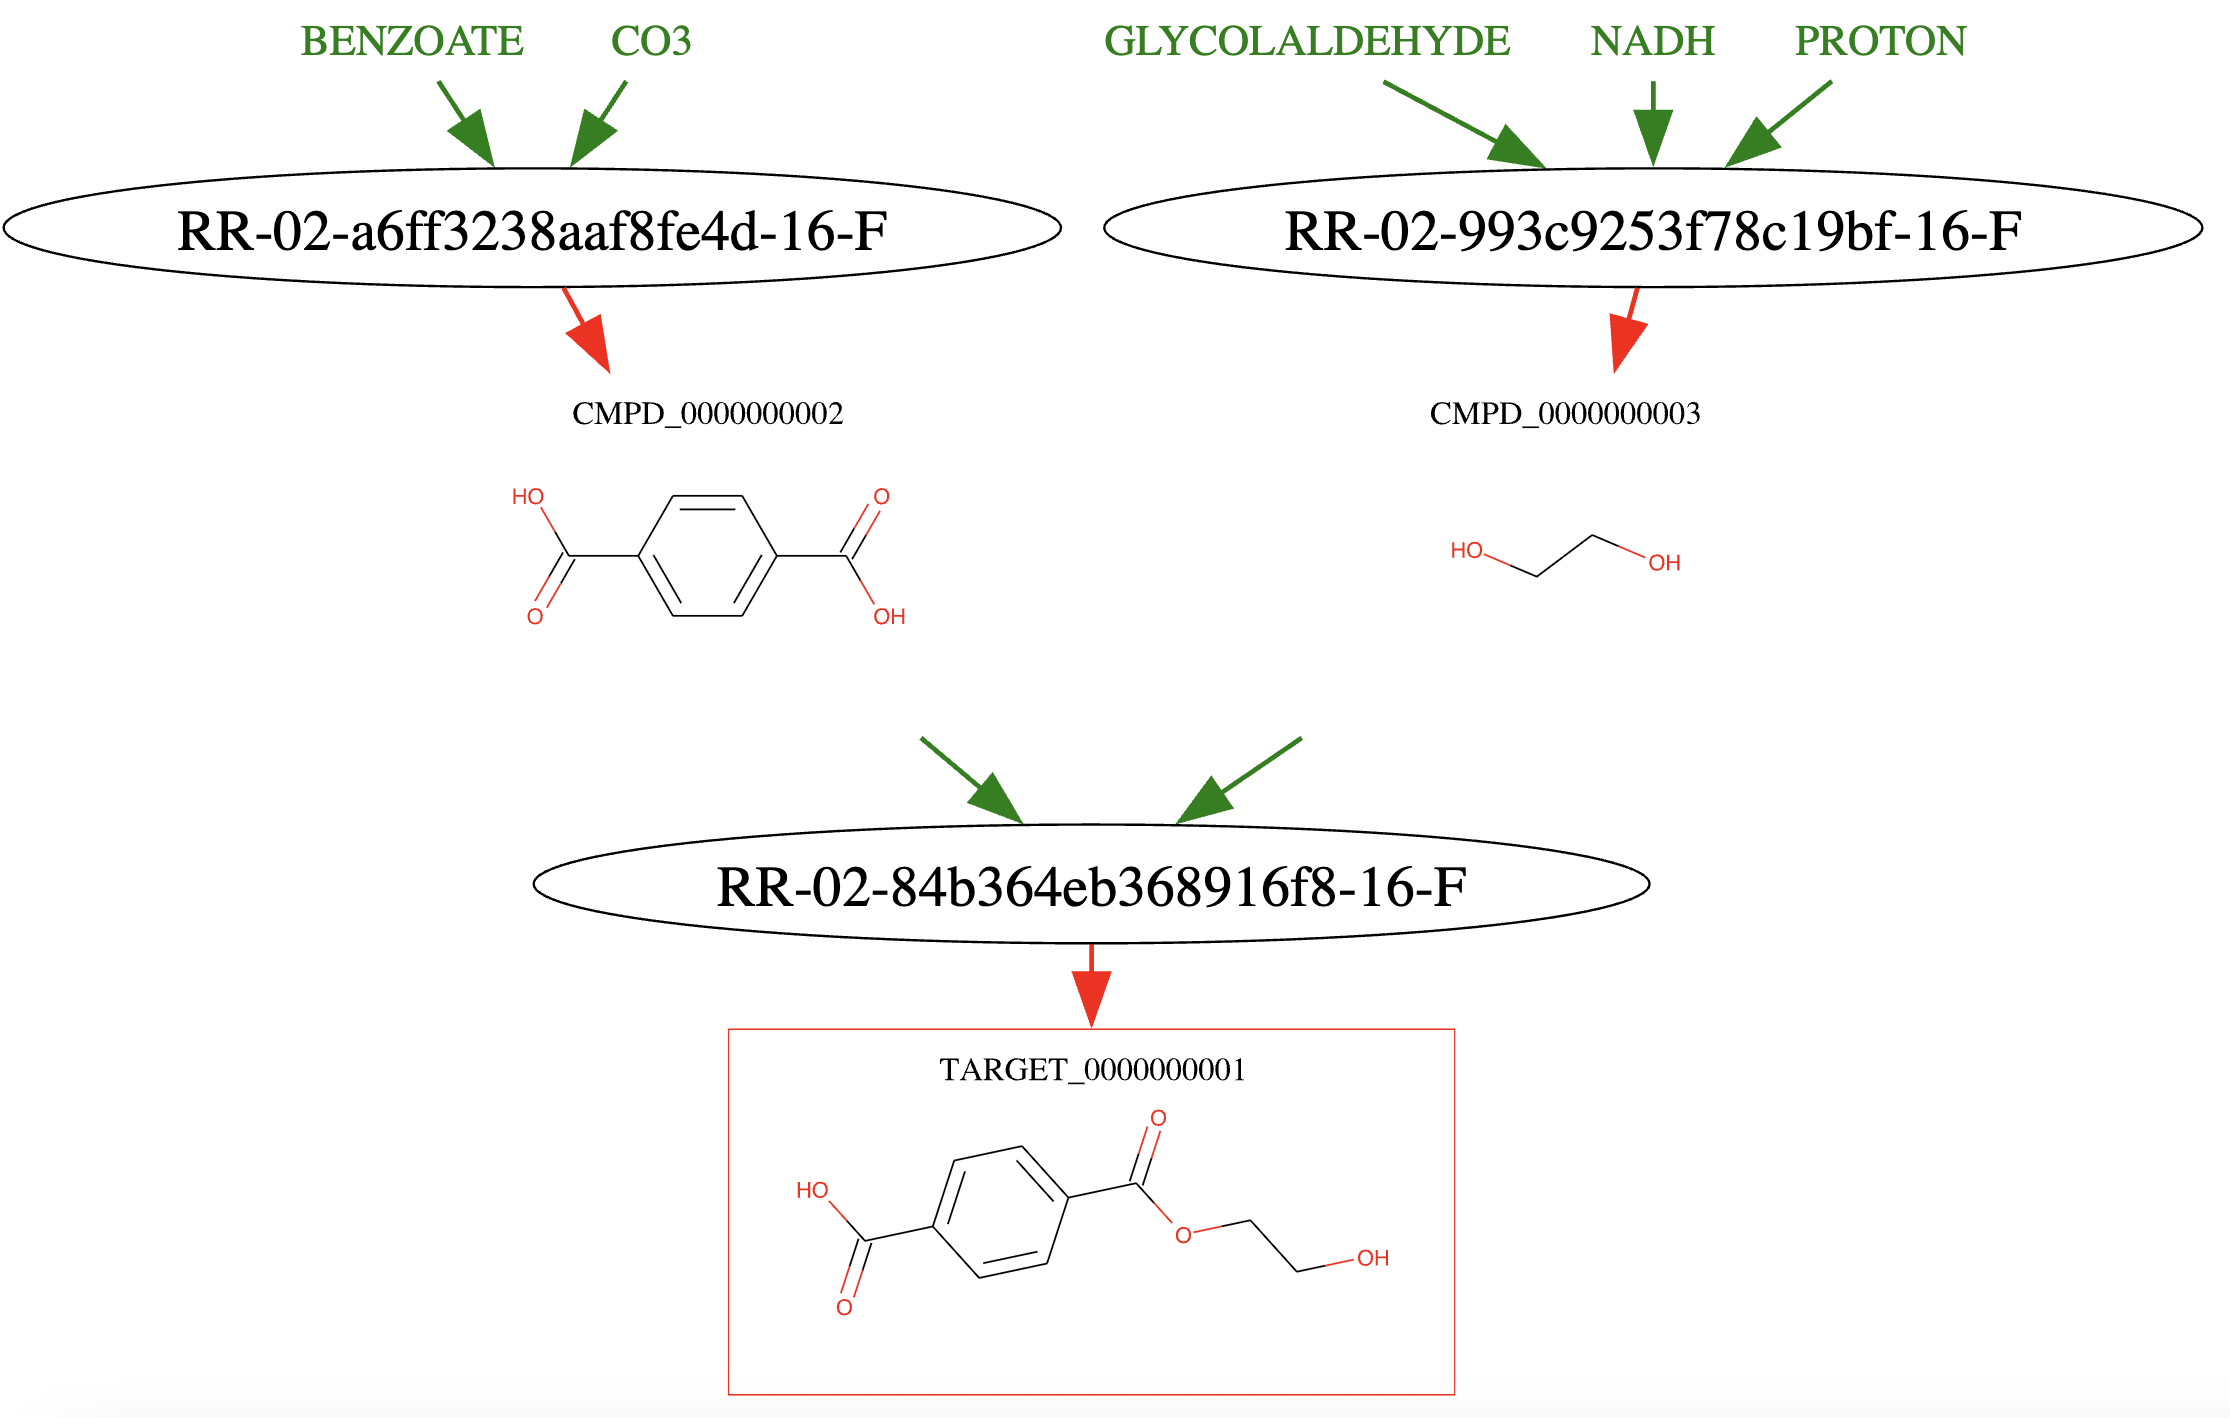

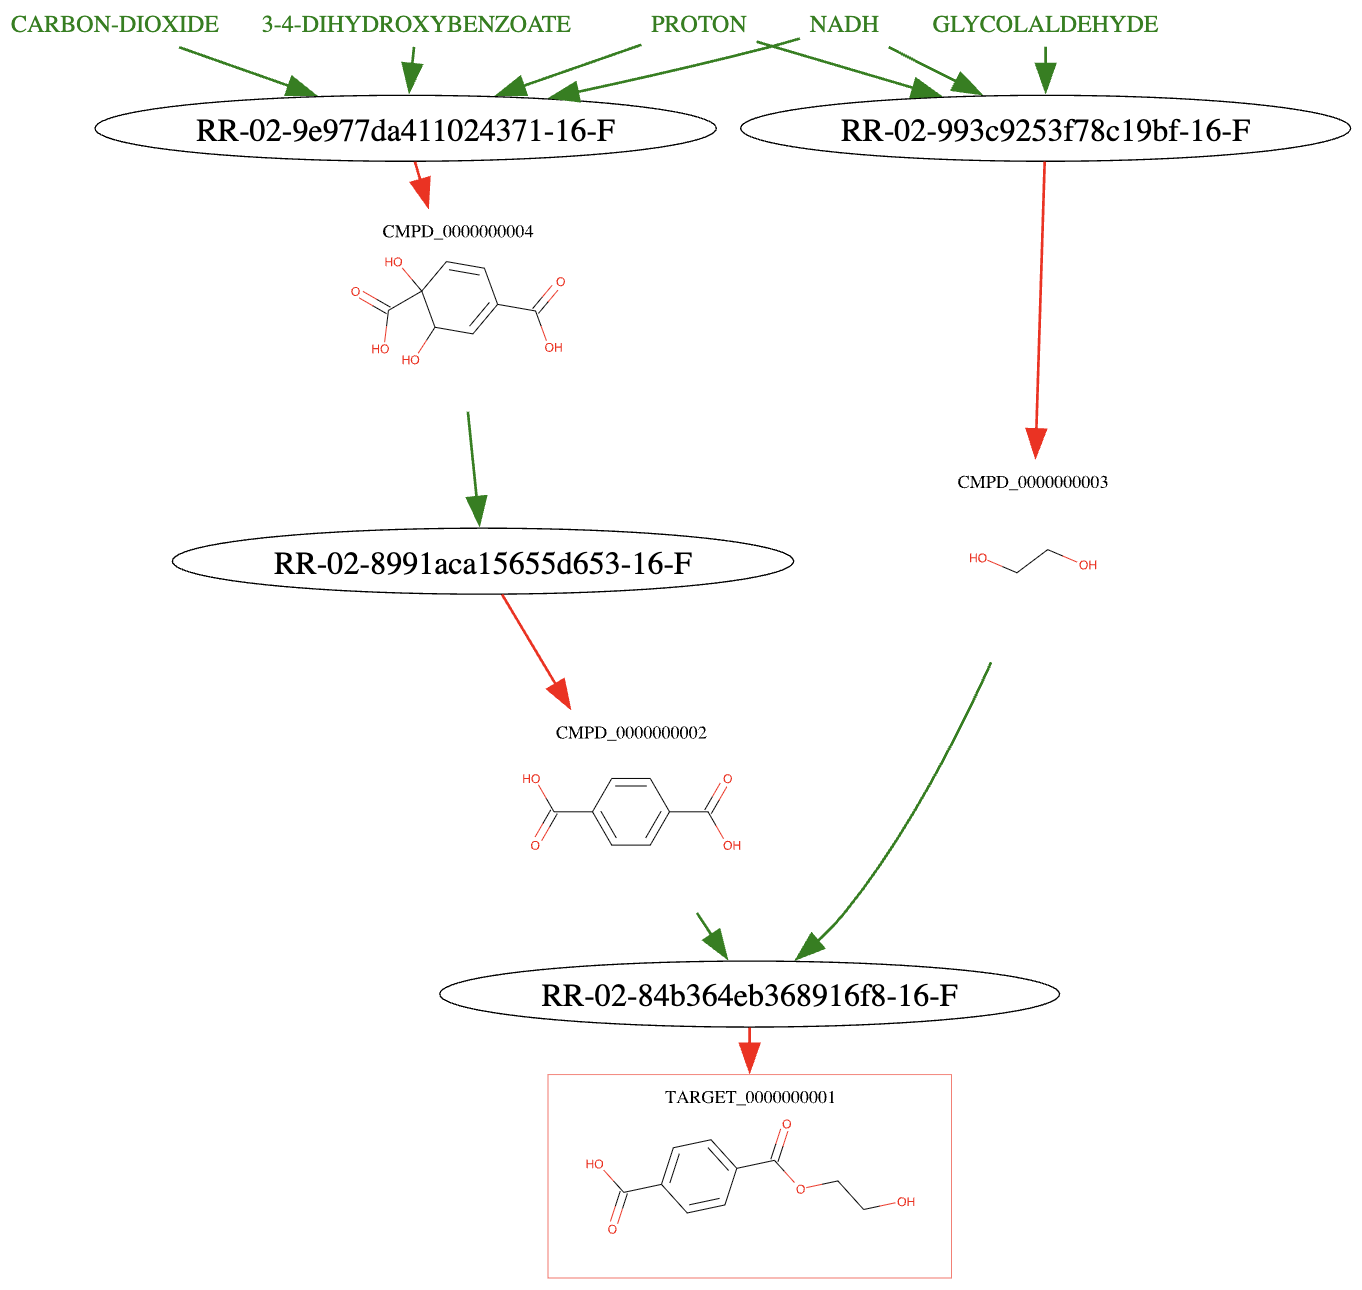

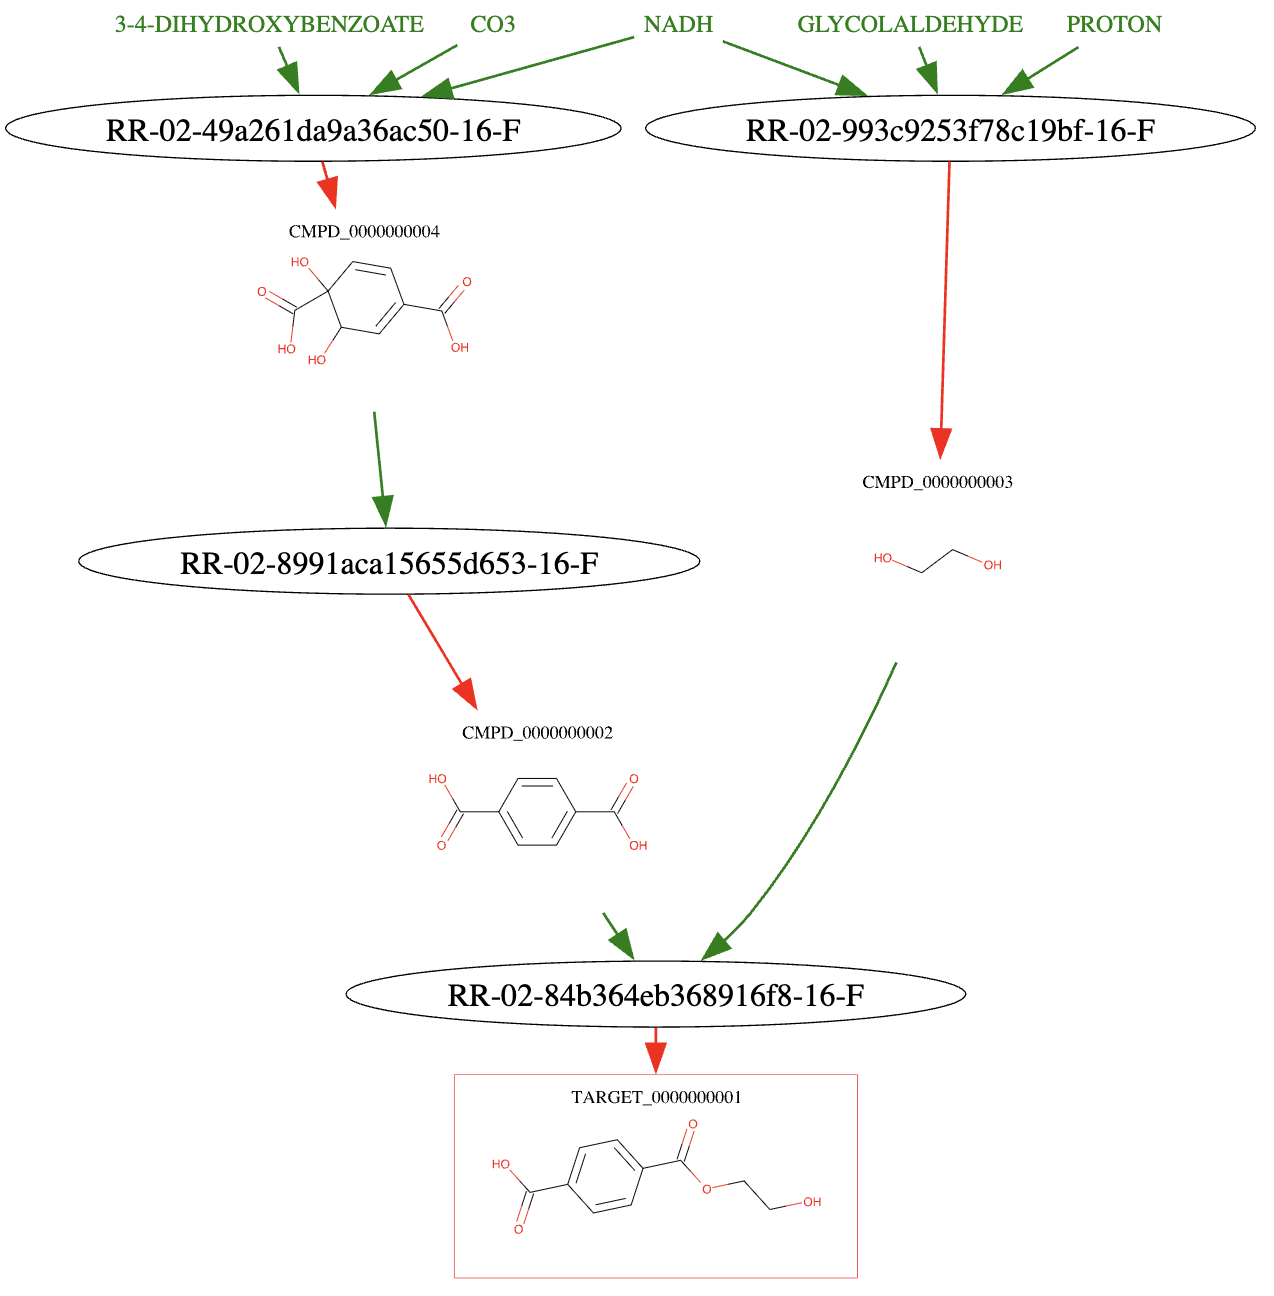


Come si può osservare, nei percorsi predetti è presente il 3,4-diidrossibenzoato, e controllando infatti nell'annotazione dei percorsi di KEGG:

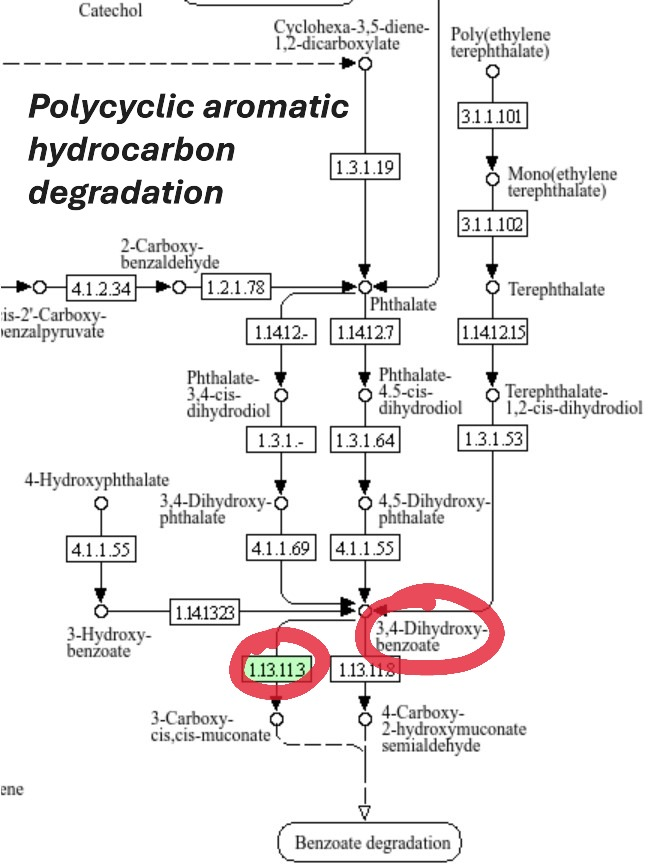

E, come si può vedere, questa via metabolica arriva ad uno dei percorsi metabolici più comuni e conosciuti: il ciclo di Krebbs (citrate cycle).

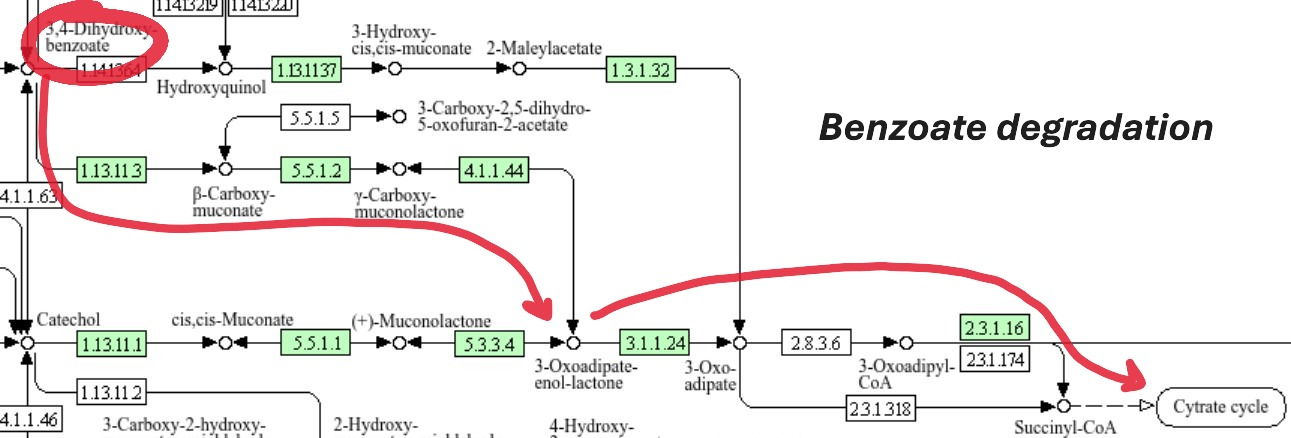
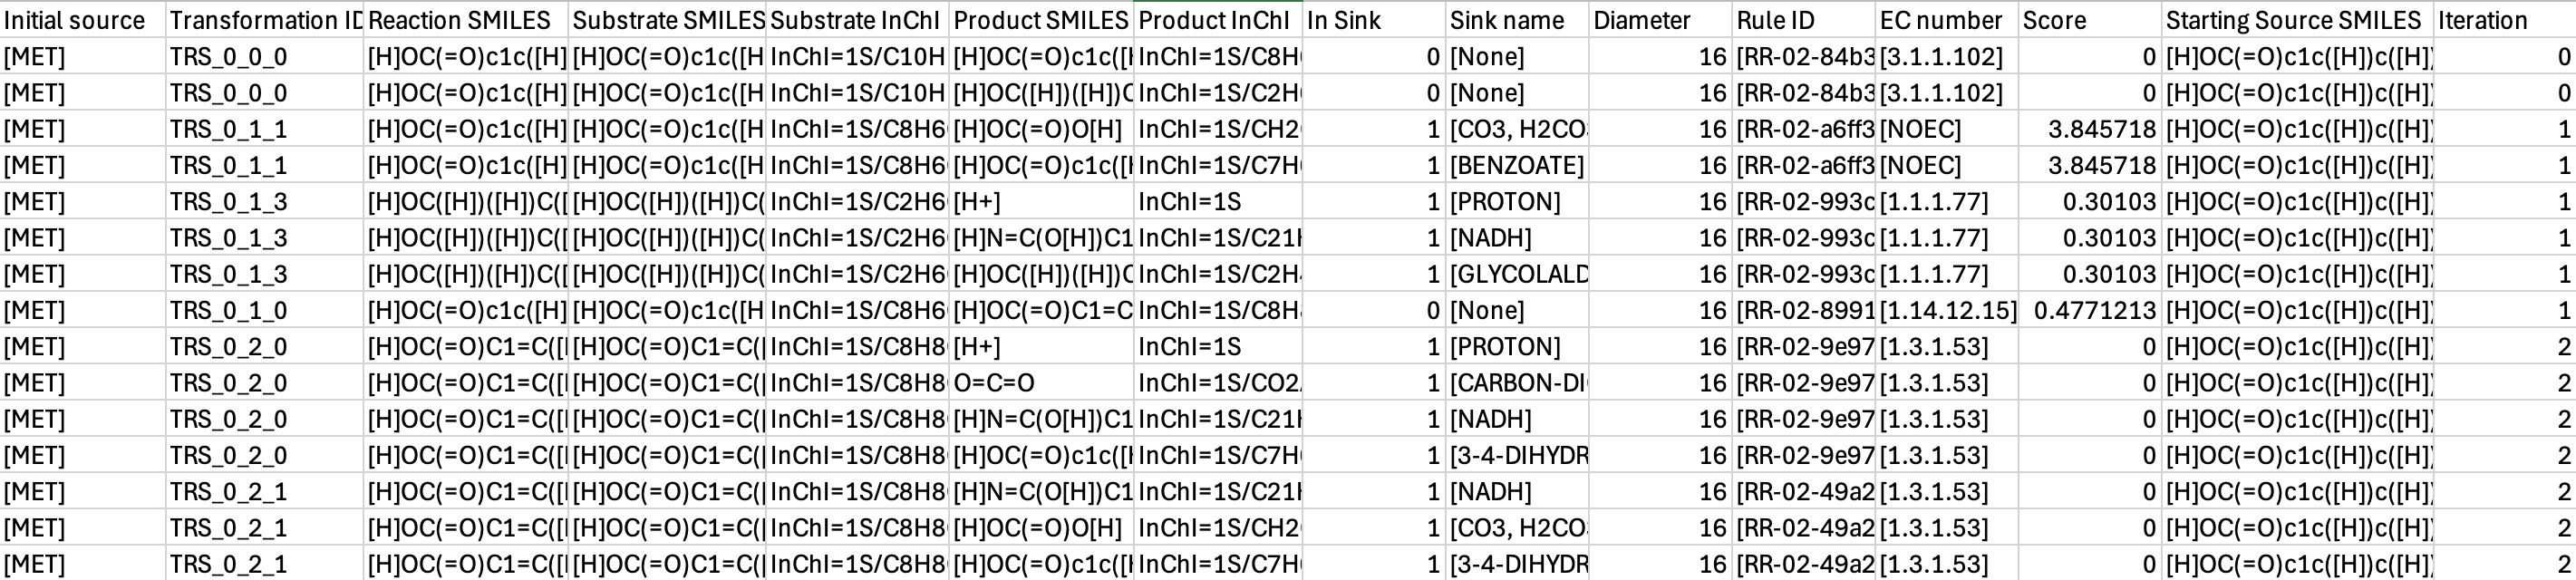

## Scope viewer

Presentiamo anche una visualizzazione molto comoda proposta dai creatori di RetroPath2.0, che consiste di un semplice file .html utile alla visualizzazione degli scope prodotti da RP. Per il nostro esempio, il diagramma è il seguente:

![Screenshot 2025-05-21 alle 23.33.34.png](<attachment:Screenshot 2025-05-21 alle 23.33.34.png>)
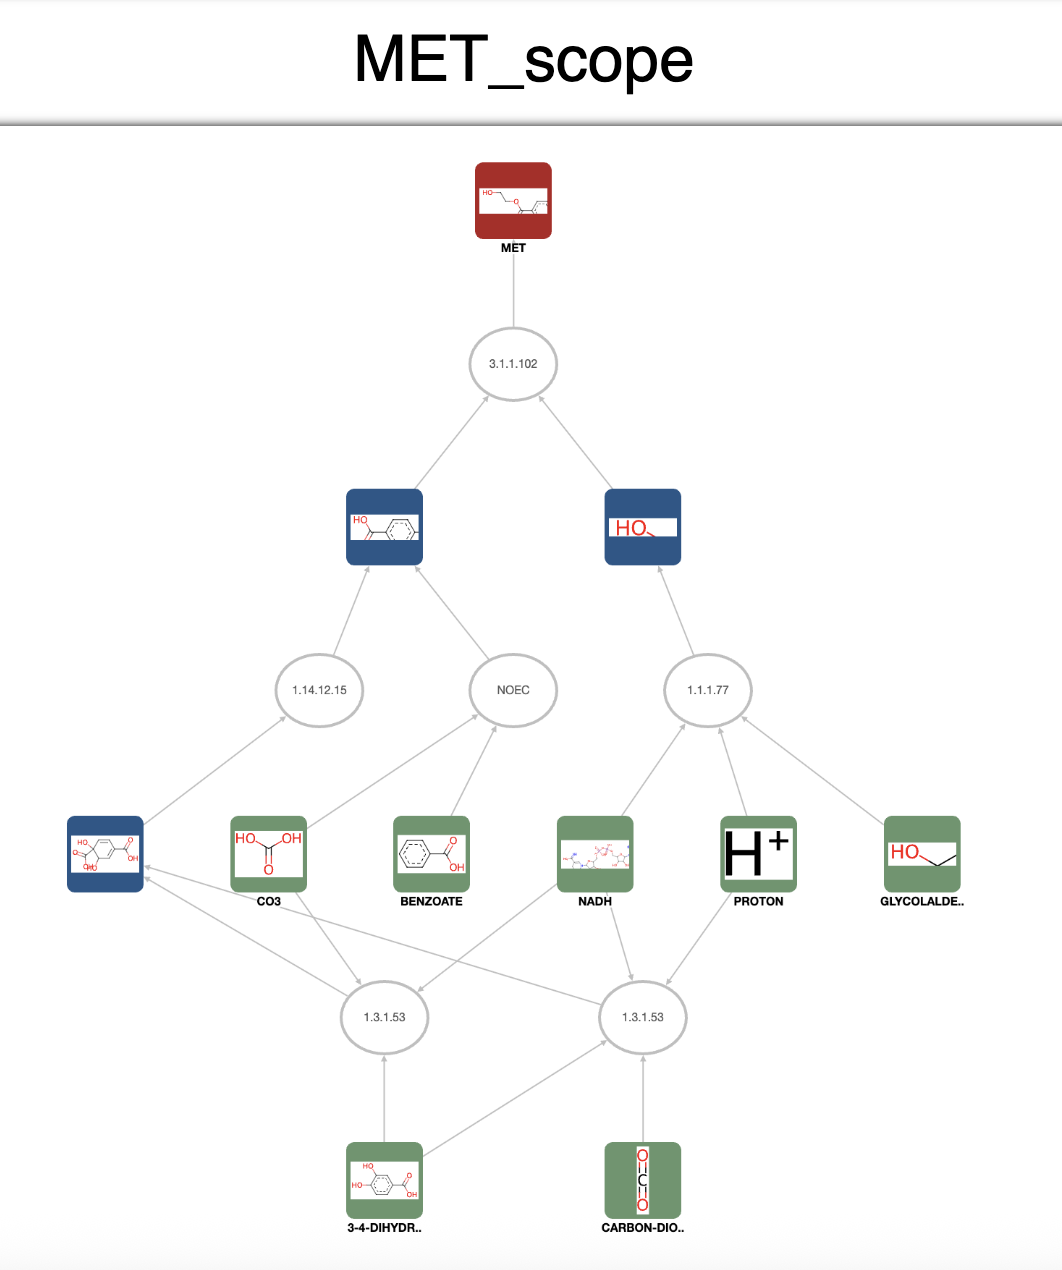

## Complessità computazionale e runtime

Di seguito riportiamo l'analisi eseguita dal comando `/usr/bin/time -v python`:

Command being timed: "python -m retropath2_wrapper data_files/biocyc_cmpd_rpcleaned.csv ../retrorules_rr02_rp2_flat_forward.csv results/ --source_file data_files/met.csv --topx 100 --dmin 6 --dmax 16 --max_steps 3"

    - User time (seconds): 322.61
    - System time (seconds): 20.21
    - Percent of CPU this job got: 329%
    - Elapsed (wall clock) time (h:mm:ss or m:ss): 1:43.97
    - Average shared text size (kbytes): 0
    - Average unshared data size (kbytes): 0
    - Average stack size (kbytes): 0
    - Average total size (kbytes): 0
    - Maximum resident set size (kbytes): 4262944
    - Average resident set size (kbytes): 0
    - Major (requiring I/O) page faults: 0
    - Minor (reclaiming a frame) page faults: 1304605
    - Voluntary context switches: 435884
    - Involuntary context switches: 3397
    - Swaps: 0
    - File system inputs: 0
    - File system outputs: 613888
    - Socket messages sent: 0
    - Socket messages received: 0
    - Signals delivered: 0
    - Page size (bytes): 4096
    - Exit status: 0

Osserviamo quindi, per questo esempio di dimensione pur sempre ridotta, un buon utilizzo di RAM (circa 4GB), un runtime discretamente corto (1 minuto e 44 secondi) e una media di 3.29 core utilizzati.

## Prossimi passi
Attualmente stiamo esplorando ulteriormente quanto offerto dalla suite di RetroPath, la quale comprende anche strumenti come **RetroPathRL** (strumento di reinforcement learning che può runnare Monte Carlo Tree Search per retrosintesi) e **rptools** (insieme di strumenti che permettono di eseguire analisi ulteriori su percorsi precedentemente predetti, come ad esempio l'aggiunta dei cofattori appropriati, analisi flussomiche e ranking dei percorsi).

Oltre alla parte di predizione dei percorsi, ci stiamo anche concentrando sulla parte cronologicamente precedente nella pipeline del tool, ovvero il riperimento di percorsi già esistenti. Per fare ciò, intendiamo servirci di alcuni parser per gestire le informazioni relative ai pathway già annotati sui vari database che vogliamo consultare (per ora KEGG e MetaCyc).

Vogliamo poi far convergere i due casi (riperimento percorsi conosciuti e predizione sconosciuti) in una serie di azioni che sia univoca; idealmente quest'ultima sarà: visualizzazione del/dei percorso/i proposto/i, reperimento degli enzimi necessari a compiere le reazioni richieste che Rhodococcus Opacus PD630 non possiede, acquisizione delle relative sequenze nucleotidiche attraverso ricerca in specie omologhe, assemblaggio del plasmide e quindi output finale.